In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/game_logs.csv", dtype={"GAME_ID": str})
df["GAME_DATE"] = pd.to_datetime(df["GAME_DATE"])

In [3]:
print(df.shape)
df.head()

(23958, 30)


,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE,SEASON
0,22015,1610612737,ATL,Atlanta Hawks,0021500001,2015-10-27,ATL vs. DET,L,240,37,...,40,22,9,4,15,25,94,-12,1,2015-16
1,22015,1610612739,CLE,Cleveland Cavaliers,0021500002,2015-10-27,CLE @ CHI,L,240,38,...,50,26,5,7,11,21,95,-2,1,2015-16
2,22015,1610612740,NOP,New Orleans Pelicans,0021500003,2015-10-27,NOP @ GSW,L,240,35,...,33,21,9,3,19,26,95,-16,1,2015-16
3,22015,1610612741,CHI,Chicago Bulls,0021500002,2015-10-27,CHI vs. CLE,W,240,37,...,47,13,6,10,13,22,97,2,1,2015-16
4,22015,1610612744,GSW,Golden State Warriors,0021500003,2015-10-27,GSW vs. NOP,W,240,41,...,56,29,8,7,20,29,111,16,1,2015-16


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23958 entries, 0 to 23957
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   SEASON_ID          23958 non-null  int64         
 1   TEAM_ID            23958 non-null  int64         
 2   TEAM_ABBREVIATION  23958 non-null  str           
 3   TEAM_NAME          23958 non-null  str           
 4   GAME_ID            23958 non-null  str           
 5   GAME_DATE          23958 non-null  datetime64[us]
 6   MATCHUP            23958 non-null  str           
 7   WL                 23958 non-null  str           
 8   MIN                23958 non-null  int64         
 9   FGM                23958 non-null  int64         
 10  FGA                23958 non-null  int64         
 11  FG_PCT             23958 non-null  float64       
 12  FG3M               23958 non-null  int64         
 13  FG3A               23958 non-null  int64         
 14  FG3_PCT          

In [5]:
games_per_id = df["GAME_ID"].value_counts()
print("Unique games:", df["GAME_ID"].nunique())
print("Rows / 2:", len(df) / 2)
print(games_per_id.value_counts())

Unique games: 11979
Rows / 2: 11979.0
count
2    11979
Name: count, dtype: int64


In [9]:
df[["GAME_DATE", "TEAM_ABBREVIATION", "MATCHUP", "WL", "PTS"]].head(10)

,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS
0,2015-10-27,ATL,ATL vs. DET,L,94
1,2015-10-27,CLE,CLE @ CHI,L,95
2,2015-10-27,NOP,NOP @ GSW,L,95
3,2015-10-27,CHI,CHI vs. CLE,W,97
4,2015-10-27,GSW,GSW vs. NOP,W,111
5,2015-10-27,DET,DET @ ATL,W,106
6,2015-10-28,LAC,LAC @ SAC,W,111
7,2015-10-28,LAL,LAL vs. MIN,L,111
8,2015-10-28,MIA,MIA vs. CHA,W,104
9,2015-10-28,MIL,MIL vs. NYK,L,97


In [14]:
print(df["WL"].value_counts(dropna=False))
df["IS_HOME"] = df["MATCHUP"].str.contains("vs.", regex=False)
df["WIN"] = (df["WL"] == "W").astype(int)

WL
L    11979
W    11979
Name: count, dtype: int64


In [16]:
home = df[df["IS_HOME"]].copy()
print("Overall home win rate:", home["WIN"].mean())
home_by_season = home.groupby("SEASON")["WIN"].mean()
print(home_by_season)

Overall home win rate: 0.5655587105395022
SEASON
2015-16    0.588618
2016-17    0.583740
2017-18    0.578862
2018-19    0.592683
2019-20    0.551464
2020-21    0.543519
2021-22    0.543902
2022-23    0.580488
2023-24    0.543089
2024-25    0.544490
Name: WIN, dtype: float64


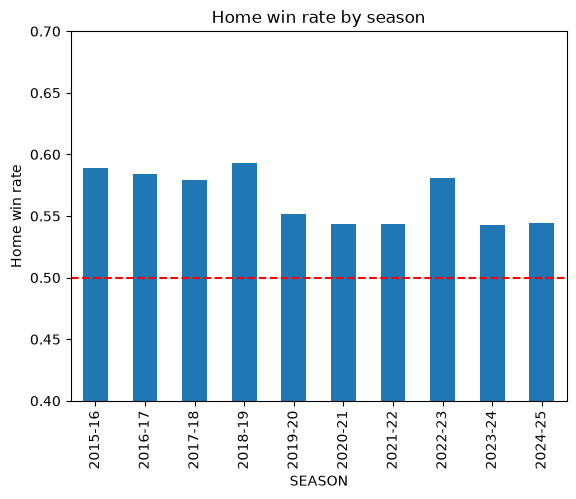

In [17]:
home_by_season.plot(kind="bar")
plt.axhline(0.5, color="red", linestyle="--")
plt.ylabel("Home win rate")
plt.title("Home win rate by season")
plt.ylim(0.4, 0.7)
plt.show()

In [18]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

SEASON_ID            0
TEAM_ID              0
TEAM_ABBREVIATION    0
TEAM_NAME            0
GAME_ID              0
GAME_DATE            0
MATCHUP              0
WL                   0
MIN                  0
FGM                  0
FGA                  0
FG_PCT               0
FG3M                 0
FG3A                 0
FG3_PCT              0
FTM                  0
FTA                  0
FT_PCT               1
OREB                 0
DREB                 0
REB                  0
AST                  0
STL                  0
BLK                  0
TOV                  0
PF                   0
PTS                  0
PLUS_MINUS           0
VIDEO_AVAILABLE      0
SEASON               0
IS_HOME              0
WIN                  0
dtype: int64
Duplicate rows: 0


,SEASON_ID,TEAM_ID,GAME_DATE,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE,WIN
count,23958.000000,2.395800e+04,23958,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,...,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.000000,23958.00000
mean,22019.500877,1.610613e+09,2020-07-21 09:48:40.210368,241.550630,40.641456,87.678312,0.464441,11.586610,32.236664,0.358423,...,44.048835,24.509558,7.673721,4.861842,14.078387,19.785207,110.259412,0.000000,1.010351,0.50000
min,22015.000000,1.610613e+09,2015-10-27 00:00:00,240.000000,19.000000,60.000000,0.269000,0.000000,4.000000,0.000000,...,22.000000,7.000000,0.000000,0.000000,1.000000,4.000000,64.000000,-73.000000,0.000000,0.00000
25%,22017.000000,1.610613e+09,2017-12-30 00:00:00,240.000000,37.000000,83.000000,0.427000,9.000000,27.000000,0.300000,...,40.000000,21.000000,6.000000,3.000000,11.000000,17.000000,101.000000,-9.000000,1.000000,0.00000
50%,22020.000000,1.610613e+09,2020-12-23 00:00:00,240.000000,41.000000,87.000000,0.463000,11.000000,32.000000,0.357000,...,44.000000,24.000000,7.000000,5.000000,14.000000,20.000000,110.000000,0.000000,1.000000,0.50000
75%,22022.000000,1.610613e+09,2023-01-21 00:00:00,240.000000,44.000000,92.000000,0.500000,14.000000,38.000000,0.417000,...,48.000000,28.000000,10.000000,6.000000,17.000000,23.000000,119.000000,9.000000,1.000000,1.00000
max,22024.000000,1.610613e+09,2025-04-13 00:00:00,340.000000,65.000000,128.000000,0.689000,29.000000,70.000000,0.842000,...,74.000000,50.000000,22.000000,20.000000,31.000000,42.000000,176.000000,73.000000,2.000000,1.00000
std,2.909421,8.650242e+00,NaN,6.848543,5.288528,7.252130,0.054911,4.050655,7.976350,0.087761,...,6.590905,5.273397,2.933602,2.490075,3.923150,4.266602,12.972180,14.682802,0.102853,0.50001
